# Using Diffusion on prediction of video and motion

## Import the lib and initialize the parameters

In [1]:
import argparse
import os.path

import torch
from torch import nn,optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/data_20240807_processed')

parser.add_argument('--sequence_length', type=int, default=16)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])

cuda


## 1. Load the Dataset

In [3]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=False, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/data_20240807_processed/train/metadata_16.pkl
metadata exists in: dataset/data_20240807_processed/test/metadata_16.pkl


## 2. Load the networks

In [4]:
from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator()

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])

## 3. Train the model

### 3.1 Continue from the checkpoint

In [5]:
from TimeSformer.VDT_vm import VDT

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 100
in_channels = 4
input_size = 8

eps_est_model = VDT(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=16,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)

modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
checkpoint = torch.load(modelData)
vae.load_state_dict(checkpoint['model_state_dict'])
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False


## 4. Tests

### 4.1 DDIM for generation

In [6]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: dataset/data_20240807_processed/train/metadata_16.pkl


load model: success
li:0.211 ang:-0.400
li:0.135 ang:-0.400
li:0.190 ang:-0.400
li:0.221 ang:-0.400
li:0.248 ang:-0.100
li:0.190 ang:0.000
li:0.282 ang:0.000
li:0.265 ang:0.000
torch.Size([1, 16, 8, 8, 4])
li:0.303 ang:-0.106
li:0.205 ang:-0.004
li:0.209 ang:-0.129
li:0.199 ang:-0.294
li:0.156 ang:-0.186
li:0.238 ang:-0.125
li:0.218 ang:-0.125
li:0.277 ang:-0.210
tensor(True)
li:0.188 ang:-0.035
li:0.193 ang:-0.024
li:0.163 ang:-0.298
li:0.305 ang:-0.226
li:0.220 ang:0.182
li:0.241 ang:0.071
li:0.219 ang:-0.115
li:0.350 ang:-0.020
tensor(True)
li:0.315 ang:-0.175
li:0.169 ang:0.166
li:0.273 ang:-0.037
li:0.252 ang:-0.208
li:0.157 ang:-0.047
li:0.199 ang:-0.157
li:0.310 ang:-0.438
li:0.207 ang:-0.467
tensor(True)
li:0.208 ang:-0.097
li:0.261 ang:-0.138
li:0.252 ang:-0.192
li:0.206 ang:-0.265
li:0.151 ang:-0.015
li:0.208 ang:0.010
li:0.179 ang:-0.134
li:0.240 ang:-0.074
tensor(True)
li:0.179 ang:-0.050
li:0.155 ang:0.006
li:0.275 ang:-0.360
li:0.181 ang:-0.310
li:0.219 ang:-0.208
li:0.13

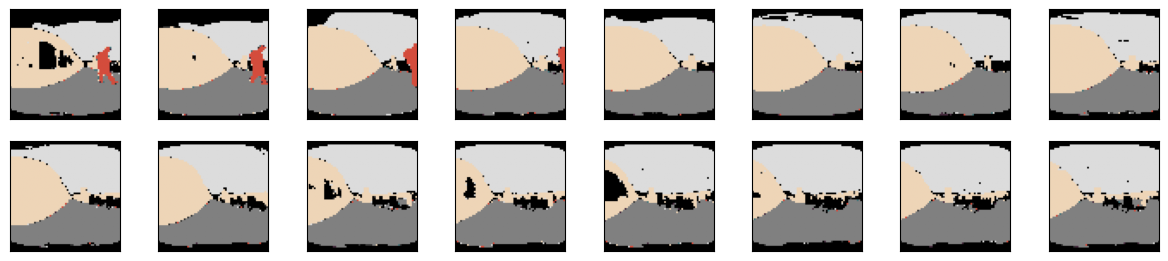

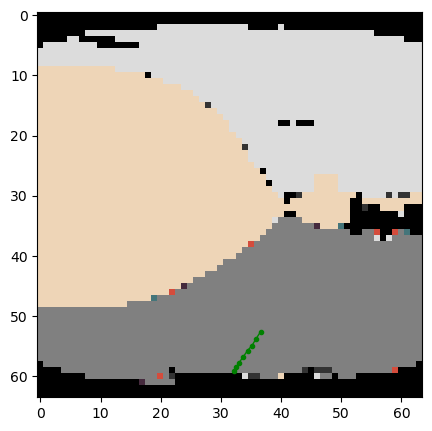

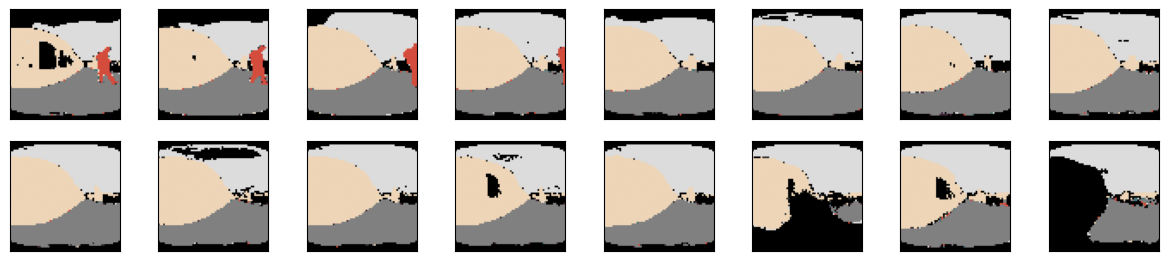

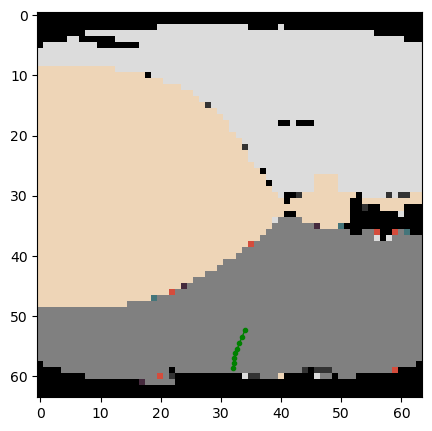

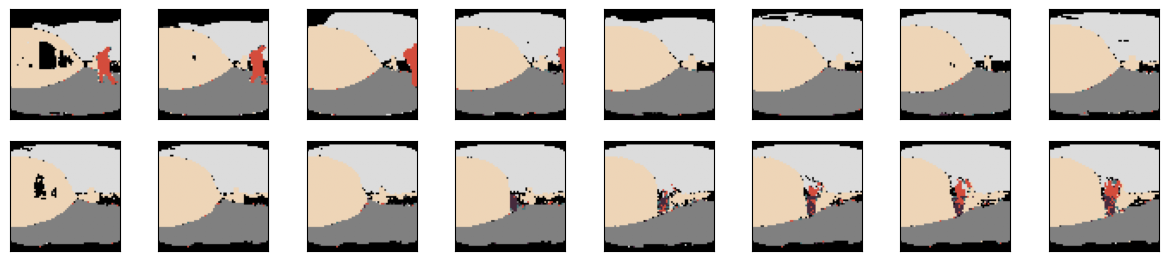

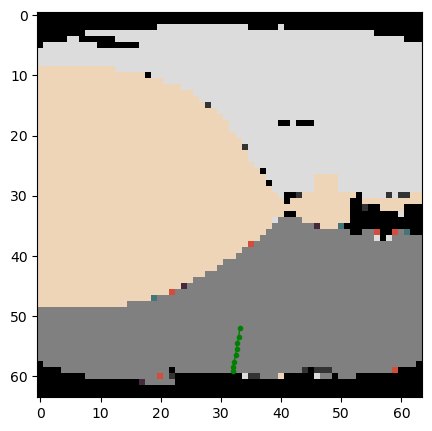

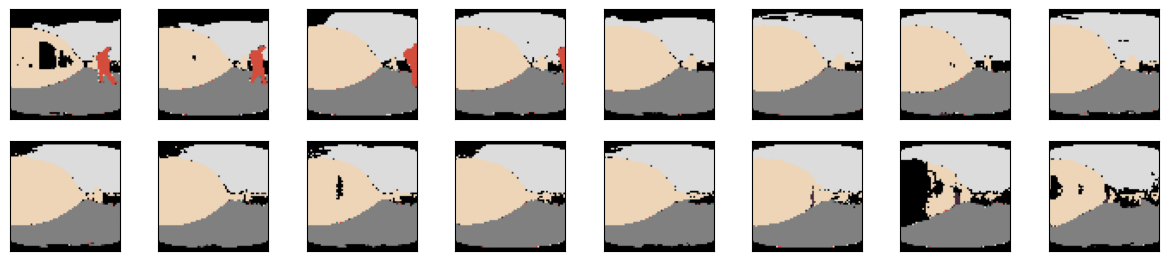

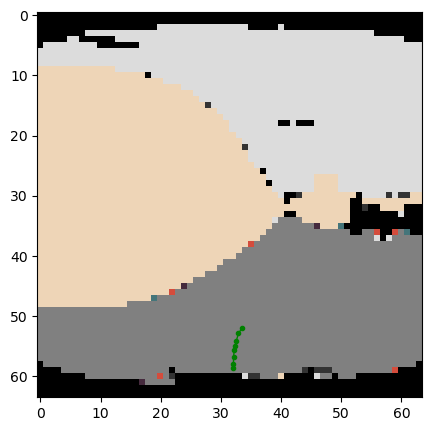

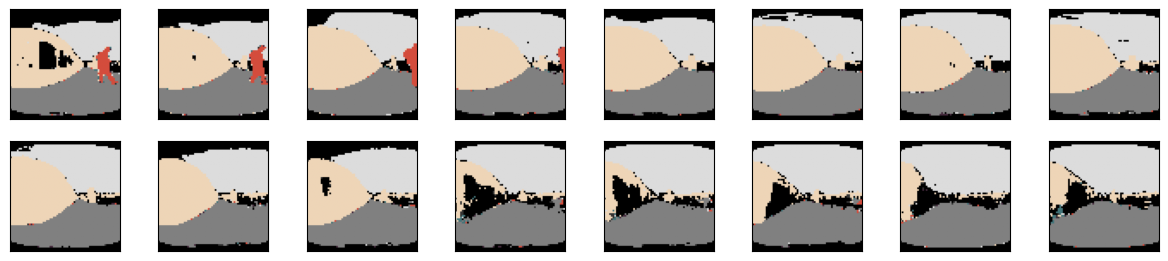

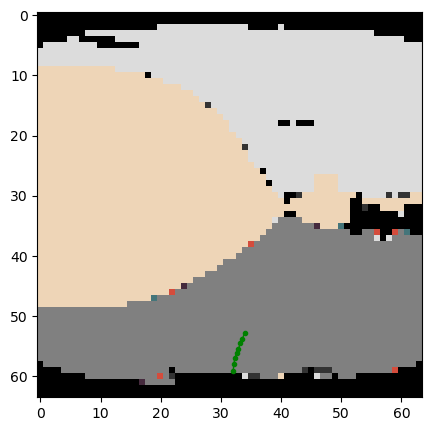

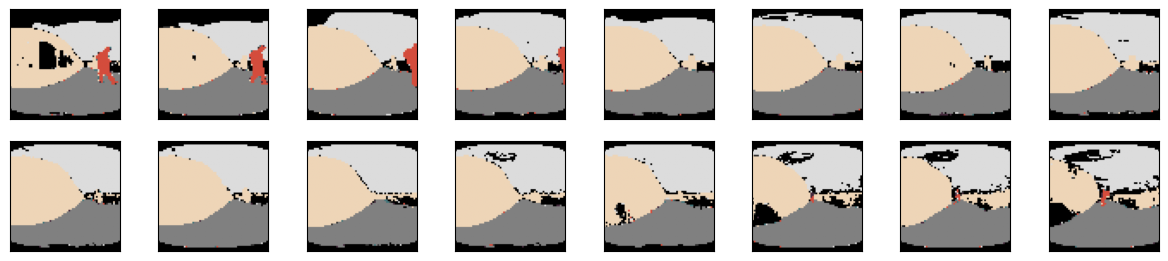

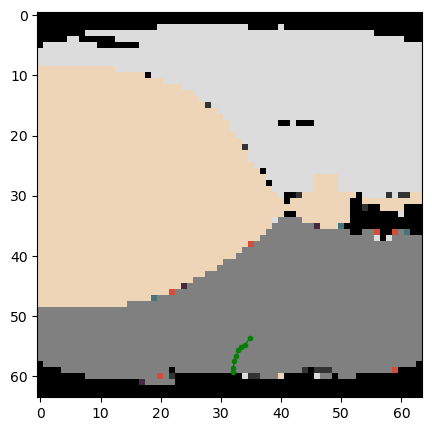

In [7]:
from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

# modelData = '/home/xu/xu/robo_nav/checkpoints_VDT_vae/VDT_seg_vae_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_seg/VDT_20240807_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels,depth=depth, hidden_size=hidden_size, model_path=modelData, _cuda=0)

idx=100 
# memo: data20240807 1720, 210, 510, 500, 3500

vis_id = 0 # the index for visualization, default = 0
pred_num = 5 # The number of multiple predictions
r=3
rec_vid_list = []
rec_mot_list = []

test = True
batch,_,_ = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,16).permute(0,2,1).to(DEVICE)

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)
a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)

rec_mot_list = []

start_time = time.time()
################ Original image #############################
batch = batch.permute(0,3,1,2)
batch_rgb = gray2color(batch)
batch_rgb = torch.clamp(batch_rgb, 0,1)
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,16,2), rgb=True)

# visual_img(batch.permute(0,2,3,1).reshape(1,16,64,64,9), b[vis_id].reshape(1,16,2))
if test:
    diff_a = torch.randn([pred_num,16,input_size,input_size,in_channels]).to(DEVICE)
    diff_b = torch.randn([pred_num,16,2]).to(DEVICE)
else:
    t = torch.tensor([args.iteration_num -1])
    diff_a, eps_vid = fw_diffusion_vid(a, alpha_cum, t)
    diff_b, eps_mot = fw_diffusion_mot(b, alpha_cum, t)

# 0:prediction 1:backward 2:interpolation
mask_vid, mask_motion = mask_generator(diff_a,diff_b,0)
print(a.shape)
a = a.repeat(pred_num,1,1,1,1)
b = b.repeat(pred_num,1,1)
diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

with torch.no_grad():
    
    rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps

rec_vid = rec_vid.reshape(pred_num,16,input_size,input_size,in_channels).permute(0,1,4,2,3)
    
est_time = time.time() - start_time

################ Decode image #############################
for i in range(pred_num):  
    rec_mot_list.append(rec_mot[i])    
    dec_vid = vae.decode(rec_vid[i]).sample
    dec_rgb = gray2color(dec_vid)
    dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    rec_vid_list.append(dec_rgb)

################ Select image (Naive selection) #############################
for t in range(pred_num):
    end_x,end_y = visual_vid_mmot(rec_vid_list[t], [rec_mot_list[t]], rgb=True, is_road=True)
    end_x = int(end_x.numpy())
    end_y = int(end_y.numpy())
    # print(end_x, end_y)
    xx, yy = torch.meshgrid(torch.arange(args.resolution), torch.arange(args.resolution), indexing="ij")
    detect_mask = ((xx-end_y)**2 +(yy-end_x)**2) <= r **2
    detected_area = rec_vid_list[t][7][detect_mask]
    # Check the end point is on the floor
    result = torch.all(detected_area == 128/255)
    print(result)

print("estimate time:", est_time)

